In [4]:
import matplotlib.pyplot as plt
import numpy as np 

Эпизод 1

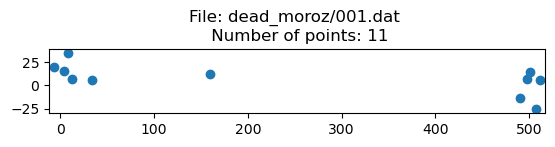

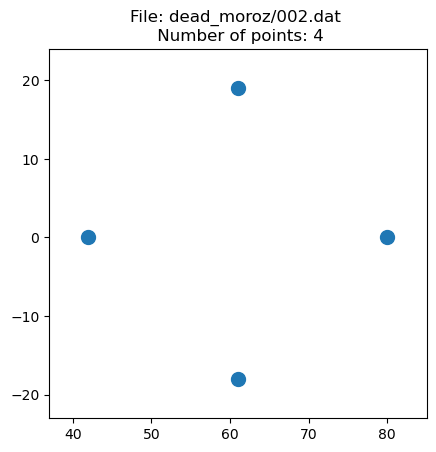

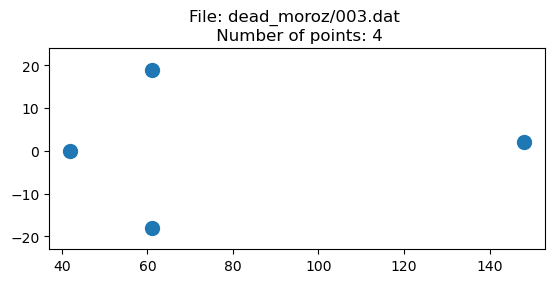

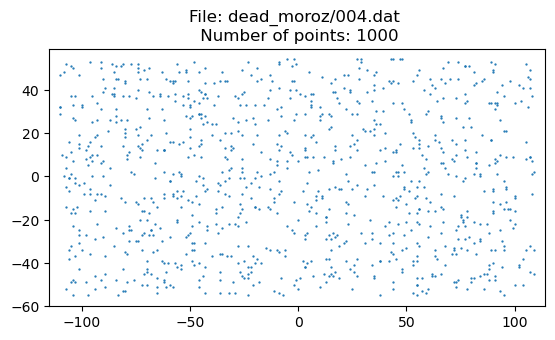

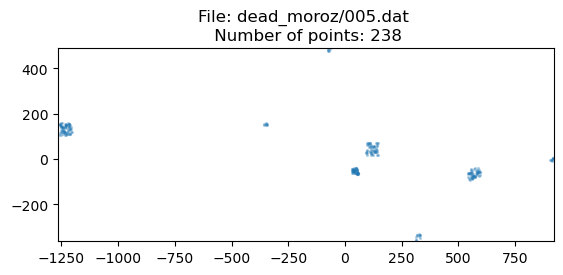

In [8]:
paths = list(input().split())
for path in paths:
    f = open(path, 'r')
    r = f.readlines()
    n = int(r[0])
    x = []
    y = []
    for i in r[1:n+1]:
        x_i, y_i = map(float, i.split(' '))
        x.append(x_i)
        y.append(y_i)
    plt.title('File: %s \n Number of points: %d' % (path, n))
    plt.scatter(x, y, s = 400/n,  alpha=1 if n/(max(y)-min(y))>1 or n<=100 else n/(max(y)-min(y)))
    plt.xlim(min(x)-5, max(x)+5)
    plt.ylim(min(y)-5, max(y)+5)
    plt.gca().set_aspect('equal')
    plt.show()

Эпизод 2

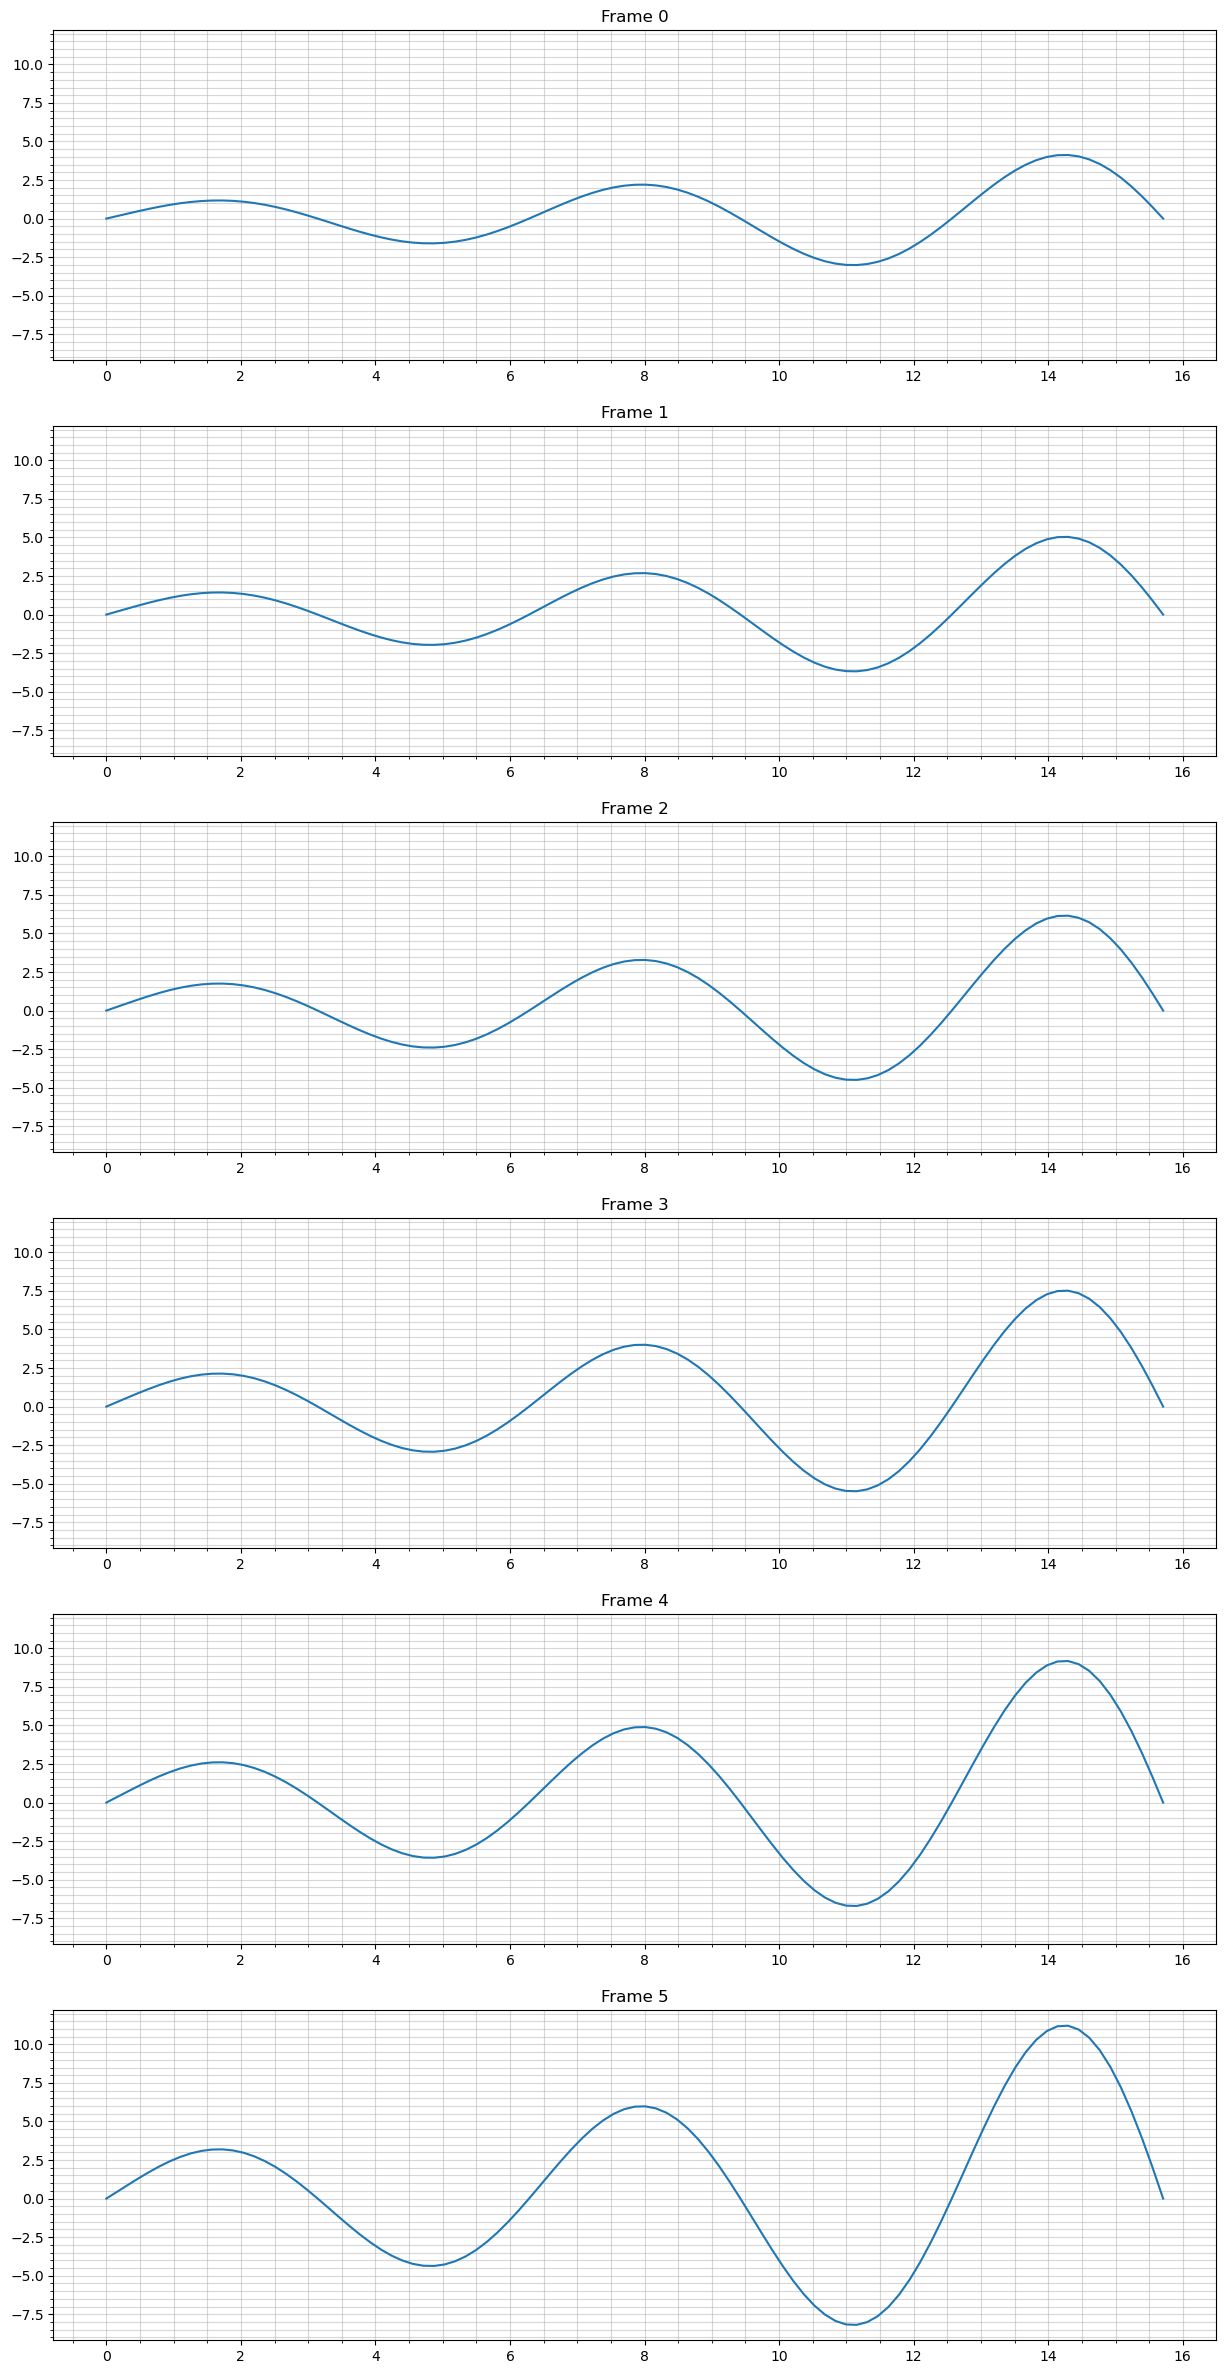

In [6]:
f = open('эпизод 2.txt', 'r')
r = f.readlines()
n = len(r)
fig, axs = plt.subplots(nrows = n//2, ncols = 1, figsize=(15, 30))
j=0
max_y = -100000
min_y = 1000000
for i in range(0, len(r)-1, 2):
    max_y = max(max_y, max(list(map(float, r[i+1].split()))))
    min_y = min(min_y, min(list(map(float, r[i+1].split()))))
    axs[j].plot(list(map(float, r[i].split())), list(map(float, r[i+1].split())))
    j+=1

j=0
for ax in axs:
    ax.set_ylim(min_y-1, max_y+1)
    ax.set_title('Frame %d' % j)
    j+=1
    ax.minorticks_on()
    ax.grid(True, which='both', alpha=0.5)
    #ax.set_aspect('equal')


plt.show()

Эпизод 3

['prep1;751;8\n', 'prep1;751;5\n', 'prep1;751;4\n', 'prep1;751;5\n', 'prep1;751;4\n', 'prep1;751;5\n', 'prep1;753;8\n', 'prep1;753;4\n', 'prep1;753;3\n', 'prep1;753;7\n', 'prep1;753;7\n', 'prep1;754;10\n', 'prep1;754;6\n', 'prep1;754;8\n', 'prep1;755;5\n', 'prep1;755;7\n', 'prep1;755;5\n', 'prep2;751;5\n', 'prep2;751;9\n', 'prep2;751;9\n', 'prep2;752;7\n', 'prep2;752;9\n', 'prep2;752;7\n', 'prep2;753;7\n', 'prep2;753;8\n', 'prep2;754;7\n', 'prep2;754;5\n', 'prep2;754;10\n', 'prep2;755;7\n', 'prep2;755;6\n', 'prep2;755;9\n', 'prep2;756;5\n', 'prep2;756;7\n', 'prep2;756;8\n', 'prep3;751;8\n', 'prep3;751;9\n', 'prep3;751;7\n', 'prep3;751;4\n', 'prep3;751;8\n', 'prep3;752;8\n', 'prep3;752;7\n', 'prep3;752;10\n', 'prep3;753;9\n', 'prep3;753;8\n', 'prep3;753;3\n', 'prep3;756;5\n', 'prep3;756;6\n', 'prep3;756;10\n', 'prep4;751;3\n', 'prep4;752;4\n', 'prep4;752;4\n', 'prep4;752;6\n', 'prep4;754;4\n', 'prep4;754;4\n', 'prep4;754;3\n', 'prep4;754;5\n', 'prep4;754;5\n', 'prep4;754;4\n', 'prep4;75

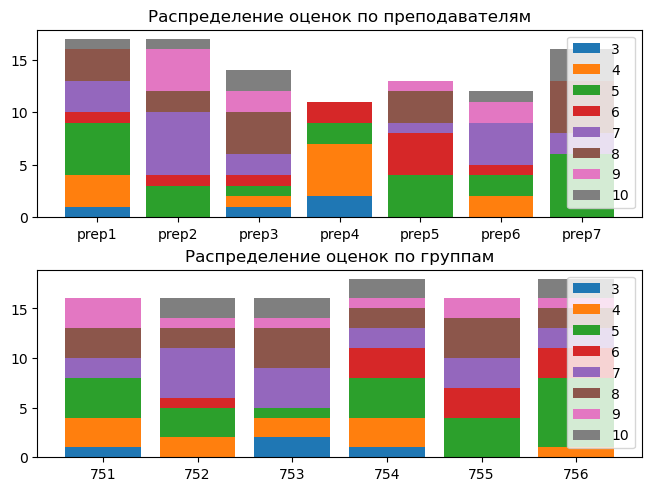

In [21]:
f = open('students.csv', 'r')
r = f.readlines()
print(r)
preps = sorted(list(set(i.split(';')[0] for i in r)))
marks_per_preps = [[] for i in range(len(preps))]
for i in r:
    i = list(i.split(';'))
    marks_per_preps[int(i[0][-1])-1].append(int(i[2]))
mark_x_preps = [[j.count(i) for j in marks_per_preps] for i in range(3, 11)]

fig, axs = plt.subplots(nrows=2, ncols=1, constrained_layout=True)
bottom = [0]*len(preps)
for j in range(len(mark_x_preps)):
    axs[0].bar(preps, mark_x_preps[j], bottom=bottom, label='%d' % (j+3))
    bottom = [b + v for b, v in zip(bottom, mark_x_preps[j])]
axs[0].set_title("Распределение оценок по преподавателям")
axs[0].legend()

groups = sorted(list(set(i.split(';')[1] for i in r)))
marks_per_groups = [[] for i in range(len(groups))]
for i in r:
    i = list(i.split(';'))
    marks_per_groups[int(i[1][-1])-1].append(int(i[2]))
mark_x_groups = [[j.count(i) for j in marks_per_groups] for i in range(3, 11)]

bottom = [0]*len(groups)
for j in range(len(mark_x_groups)):
    axs[1].bar(groups, mark_x_groups[j], bottom=bottom, label='%d' % (j+3))
    bottom = [b + v for b, v in zip(bottom, mark_x_groups[j])]
axs[1].set_title("Распределение оценок по группам")
axs[1].legend()

plt.show()
